<a href="https://colab.research.google.com/github/Vinay-Grewal/Brain_MRI-Tumour-CNN-Model/blob/main/BT_CNN_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import kagglehub

# Download dataset
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

# Training & Testing paths
train_dir = os.path.join(path, "Training")
test_dir = os.path.join(path, "Testing")

# Count training files
train_count = sum(len(files) for _, _, files in os.walk(train_dir))

# Count testing files
test_count = sum(len(files) for _, _, files in os.walk(test_dir))

print(f"Total training files: {train_count}")
print(f"Total testing files: {test_count}")
print(f"Total files: {train_count + test_count}")



Path to dataset files: C:\Users\Aakash\.cache\kagglehub\datasets\masoudnickparvar\brain-tumor-mri-dataset\versions\2
Total training files: 5600
Total testing files: 1600
Total files: 7200


In [2]:
%pip install kagglehub


   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   -------------------- ------------------- 1/2 [kagglehub]
   ---------------------------------------- 2/2 [kagglehub]

Note: you may need to restart the kernel to use updated packages.


In [2]:
import keras
from keras.models import Sequential
from keras.layers import Conv2D,Flatten,Dense,MaxPooling2D,Dropout
from sklearn.metrics import accuracy_score

In [3]:
%pip install tensorflow keras scikit-learn opencv-python pillow ipywidgets tqdm

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
    --------------------------------------- 5.5/351.2 MB 30.0 MB/s eta 0:00:12
   - -------------------------------------- 10.7/351.2 MB 26.4 MB/s eta 0:00:13
   - -------------------------------------- 16.3/351.2 MB 26.8 MB/s eta 0:00:13
   -- ------------------------------------- 22.0/351.2 MB 27.1 MB/s eta 0:00:13
   --- ------------------------------------ 28.0/351.2 MB 27.5 MB/s eta 0:00:12
   --- ------------------------------------ 34.3/351.2 MB 27.7 MB/s eta 0:00:12
   ---- ----------------------------------- 40.1/351.2 MB 27.5 MB/s eta 0:00:12
   ----- ---------------------------------- 44.6/351.2 MB 26.9 MB/s eta 0:00:12
   ----- ---------------------------------- 48.5/351.2 MB 26.1 MB/s eta 0:00:12
   ----- ---------------------------------- 50.9/351.2 MB 24.6 MB/s eta 0:00:13
   ------ --------------------------------- 56.4/351.2 MB 24.7 MB/s eta 0:00:12
   ------ --------------------------------- 60.8/3

In [4]:
# Importing essential libraries
import ipywidgets as widgets  # For creating interactive widgets
import io  # For handling input/output operations
from PIL import Image  # For image manipulation and processing
import tqdm  # For displaying progress bars
from sklearn.model_selection import train_test_split  # For splitting datasets
import cv2  # For image processing using OpenCV
from sklearn.utils import shuffle  # For shuffling data
import tensorflow as tf  # For building and training deep learning models
import numpy as np

In [5]:
X_train = []
Y_train = []
X_test = []
Y_test = []
image_size = 150
labels = ['glioma','meningioma','notumor','pituitary']



for i in labels:
    folderPath = os.path.join(path, 'Training', i)
    for j in os.listdir(folderPath):
        img = cv2.imread(os.path.join(folderPath,j))
        img = cv2.resize(img,(image_size,image_size))
        X_train.append(img)
        Y_train.append(i)

for i in labels:
    folderPath = os.path.join(path, 'Testing', i)

    for j in os.listdir(folderPath):
        img = cv2.imread(os.path.join(folderPath,j))
        img = cv2.resize(img,(image_size,image_size))
        X_test.append(img)
        Y_test.append(i)

X_train = np.array(X_train)
Y_train = np.array(Y_train)
X_test = np.array(X_test)
Y_test = np.array(Y_test)

In [6]:
# Convert Y_train to numbers
y_train_new = [labels.index(i) for i in Y_train]
Y_train = tf.keras.utils.to_categorical(y_train_new)

# Convert Y_test to numbers
y_test_new = [labels.index(i) for i in Y_test]
Y_test = tf.keras.utils.to_categorical(y_test_new)


In [7]:
model = Sequential()
model.add(Conv2D(32,(3,3),activation = 'relu',input_shape=(150,150,3)))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Dropout(0.3))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(Dropout(0.3))
model.add(MaxPooling2D(2,2))
model.add(Dropout(0.3))
model.add(Conv2D(128,(3,3),activation='relu'))
model.add(Conv2D(128,(3,3),activation='relu'))
model.add(Conv2D(128,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Dropout(0.3))
model.add(Conv2D(128,(3,3),activation='relu'))
model.add(Conv2D(256,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Dropout(0.3))
model.add(Flatten())
model.add(Dense(512,activation = 'relu'))
model.add(Dense(512,activation = 'relu'))
model.add(Dropout(0.3))
model.add(Dense(4,activation='softmax'))

C:\Users\Aakash\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 146, 146, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 73, 73, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 73, 73, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 71, 71, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 69, 69, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 69, 69, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 34, 34, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 34, 34, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 30, 30, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 10, 10, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,277,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,447,044 (16.96 MB)

 Trainable params: 4,447,044 (16.96 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(loss='categorical_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [10]:
# history = model.fit(X_train,y_train,epochs=20,validation_split=0.1)
history = model.fit(X_train, Y_train, epochs=20, validation_data=(X_test, Y_test))


Epoch 1/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 161s 898ms/step - accuracy: 0.3000 - loss: 1.6008 - val_accuracy: 0.4194 - val_loss: 1.1771
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 170s 972ms/step - accuracy: 0.6354 - loss: 0.8216 - val_accuracy: 0.4900 - val_loss: 1.2251
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 172s 980ms/step - accuracy: 0.7418 - loss: 0.6065 - val_accuracy: 0.5562 - val_loss: 1.1818
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 169s 967ms/step - accuracy: 0.7754 - loss: 0.5289 - val_accuracy: 0.5581 - val_loss: 1.1581
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 169s 967ms/step - accuracy: 0.8041 - loss: 0.4844 - val_accuracy: 0.5562 - val_loss: 1.1939
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 169s 968ms/step - accuracy: 0.8541 - loss: 0.3701 - val_accuracy: 0.7150 - val_loss: 0.8629
Epoch 7/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 170s 973ms/step - accuracy: 0.8873 - loss: 0.3012 - val_accuracy: 0.6637 - val_loss: 0.8676
Epoch 8/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 174s 994ms/step - accuracy: 0.9027 -

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

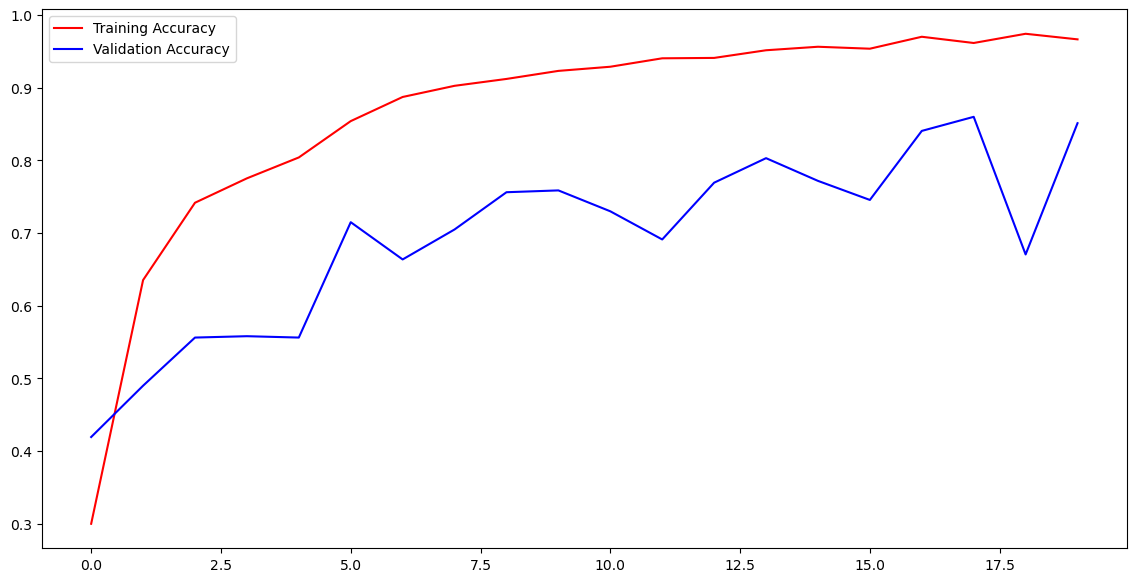

In [12]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(len(acc))
fig = plt.figure(figsize=(14,7))
plt.plot(epochs,acc,'r',label="Training Accuracy")
plt.plot(epochs,val_acc,'b',label="Validation Accuracy")
plt.legend(loc='upper left')
plt.show()

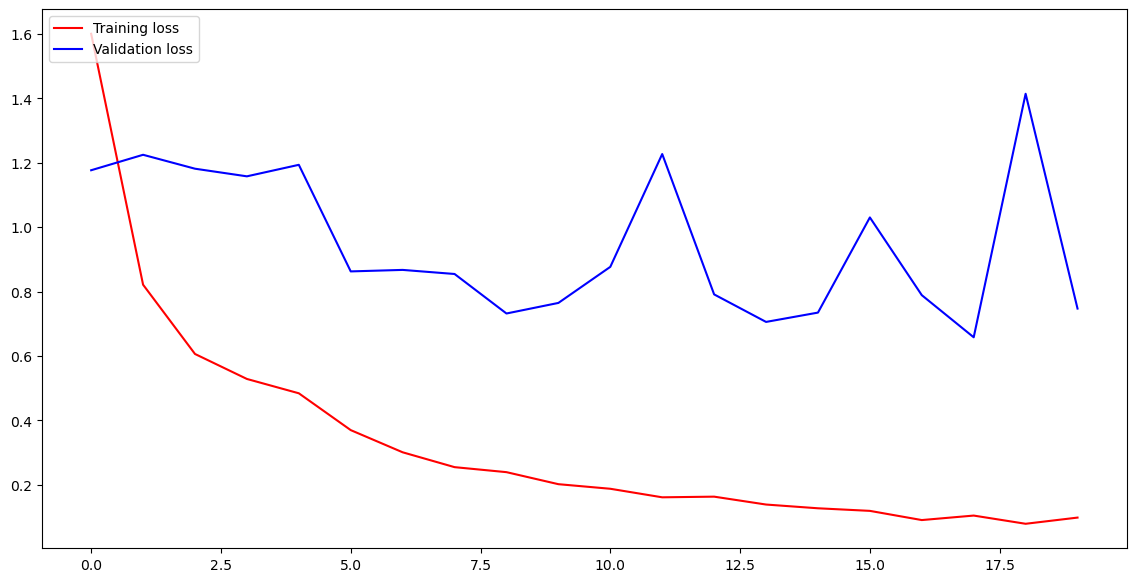

In [13]:
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(len(loss))
fig = plt.figure(figsize=(14,7))
plt.plot(epochs,loss,'r',label="Training loss")
plt.plot(epochs,val_loss,'b',label="Validation loss")
plt.legend(loc='upper left')
plt.show()

In [14]:
y_pred_probs = model.predict(X_test)                # Predicted probabilities
y_pred_classes = np.argmax(y_pred_probs, axis=1)    # Convert probabilities to class indices
y_true_classes = np.argmax(Y_test, axis=1)          # Convert one-hot test labels to class indices


50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 190ms/step


In [15]:
# Accuracy score
acc = accuracy_score(y_true_classes, y_pred_classes)
print("Test Accuracy:", acc)

Test Accuracy: 0.85125


In [16]:
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score

In [17]:
# Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
print("Confusion Matrix:\n", cm)

# Classification Report (Precision, Recall, F1-score)
print("Classification Report:\n", classification_report(y_true_classes, y_pred_classes, target_names=labels))

# Macro Precision, Recall, F1-score
precision = precision_score(y_true_classes, y_pred_classes, average='macro')
recall = recall_score(y_true_classes, y_pred_classes, average='macro')
f1 = f1_score(y_true_classes, y_pred_classes, average='macro')

print("Macro Precision:", precision)
print("Macro Recall:", recall)
print("Macro F1 Score:", f1)

Confusion Matrix:
 [[326  20  40  14]
 [ 96 271   7  26]
 [  3   0 397   0]
 [ 27   5   0 368]]
Classification Report:
               precision    recall  f1-score   support

      glioma       0.72      0.81      0.77       400
  meningioma       0.92      0.68      0.78       400
     notumor       0.89      0.99      0.94       400
   pituitary       0.90      0.92      0.91       400

    accuracy                           0.85      1600
   macro avg       0.86      0.85      0.85      1600
weighted avg       0.86      0.85      0.85      1600

Macro Precision: 0.8582211017628768
Macro Recall: 0.85125
Macro F1 Score: 0.8489108077735308


In [18]:
model.save("BT-CNN_Mode.h5")

In [19]:
model.save("BT_CNN_Model.keras")